In [1]:
from k_means_constrained import KMeansConstrained

In [2]:
import numpy as np 

In [3]:
import pandas as pd
import warnings

warnings.filterwarnings("ignore")

In [4]:
df = pd.read_csv("Route - Route.csv")

In [5]:
df.head()

,Student Name,ERP No.,Address,Clean Address,Route,"Latitude , Longitude"
0,Orchids International School,-,Orchid International School Bachupally,Orchid International School Bachupally,School,"17.557062061125425, 78.40006152438659"
1,Vishaal,2609320090,"Huda colony,chanda nagar","Huda Colony, Chanda Nagar, Hyderabad, Telangana",1,"17.492239991437522, 78.32842944232877"
2,M. Gaurangi,2609320253,My home jewel,"My Home Jewel, Miyapur, Hyderabad, Telangana",1,"17.491804778589852, 78.33762600775204"
3,M. nitya,2609320257,My home jewel,"My Home Jewel, Miyapur, Hyderabad, Telangana",1,"17.491804778589852, 78.33762600775204"
4,Dhaivik .V,2609320195,"Pranam hosptial, Madeenaguda","Pranam Hospital, Madeenaguda, Hyderabad, Telan...",1,"17.494635537783186, 78.3426860776248"


In [6]:
import pandas as pd

# Count route values
route_counts = df['Route'].value_counts()
route_counts = route_counts[route_counts.index != 'School']
route_counts.index = route_counts.index.astype(int)
# Sort routes
route_counts = route_counts.sort_index()

In [7]:
# Routes excluding 4 , 8
routes = [1,2,3,5,6,7,9,10,11,12,13,14,15,16,17,18,19,20,21]

# Your side values excluding route 8 value
target_values = [
    40,40,50,36,40,34,
    50,50,40,40,40,40,40,
    40,40,31,34,40,26
]

# Final dataframe
final_df = pd.DataFrame({
    'Route': routes,
    'Student count': route_counts.values,
    'Bus capacity': target_values,
    'Freespace' : target_values - route_counts.values
})

In [8]:
# Transpose rows and columns
df_transposed = final_df.T

# Optional: make first row as header
df_transposed.columns = df_transposed.iloc[0]
df_transposed = df_transposed[1:]

# Add total column
df_transposed["Total"] = df_transposed.sum(axis=1)

# Styled table
styled_df = (
    df_transposed.style
    .set_properties(**{
        'text-align': 'center',
        'border': '1px solid black'
    })
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('background-color', '#1F4E78'),
                ('color', 'white'),
                ('padding', '10px'),
                ('text-align', 'center')
            ]
        },
        {
            'selector': 'td',
            'props': [
                ('padding', '8px')
            ]
        }
    ])
)

display(styled_df)

Route,1,2,3,5,6,7,9,10,11,12,13,14,15,16,17,18,19,20,21,Total
Student count,39,29,29,34,35,24,47,45,24,24,37,50,42,34,34,18,37,36,21,639
Bus capacity,40,40,50,36,40,34,50,50,40,40,40,40,40,40,40,31,34,40,26,751
Freespace,1,11,21,2,5,10,3,5,16,16,3,-10,-2,6,6,13,-3,4,5,112


In [9]:
import matplotlib.pyplot as plt

In [10]:
# Split into two columns
df[['Latitude', 'Longitude']] = df['Latitude , Longitude'].str.split(',', expand=True)

# Remove extra spaces
df['Latitude'] = df['Latitude'].str.strip()
df['Longitude'] = df['Longitude'].str.strip()

In [11]:
df['Latitude'] = pd.to_numeric(df['Latitude'], errors='coerce')
df['Longitude'] = pd.to_numeric(df['Longitude'], errors='coerce')

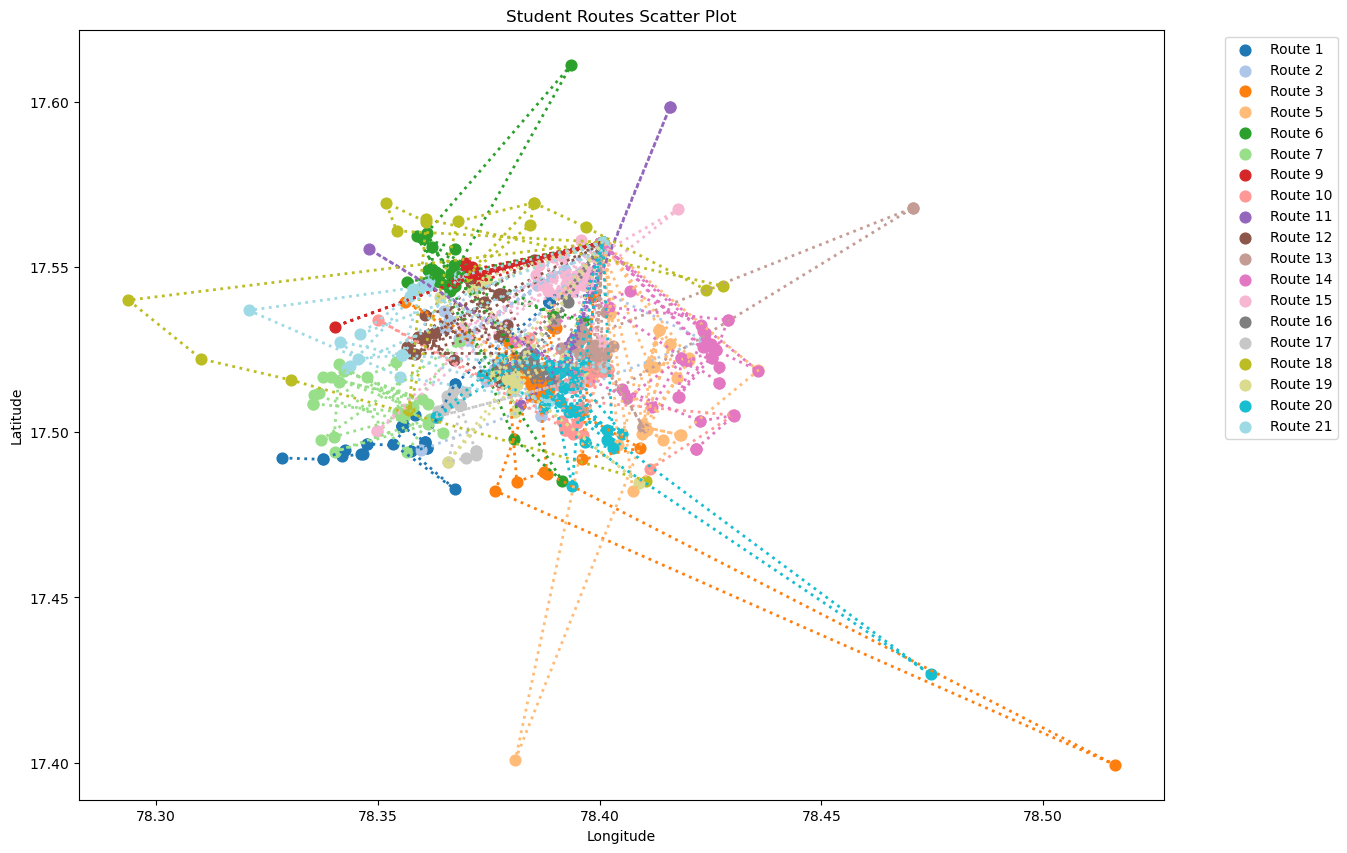

In [12]:
# Convert columns to numeric
df['Route'] = pd.to_numeric(df['Route'], errors='coerce')

# Keep only valid rows
plot_data = df.dropna(subset=['Latitude', 'Longitude', 'Route']).copy()

# Sort routes
routes = sorted(plot_data['Route'].unique())

# Create plot
plt.figure(figsize=(14,10))

# Colormap
cmap = plt.cm.get_cmap('tab20', len(routes))

# Plot each route separately
for i, route in enumerate(routes):

    route_data = plot_data[plot_data['Route'] == route]

    # Scatter points
    plt.scatter(
        route_data['Longitude'],
        route_data['Latitude'],
        color=cmap(i),
        s=60,
        label=f'Route {int(route)}'
    )

    # Join points with dotted line
    plt.plot(
        route_data['Longitude'],
        route_data['Latitude'],
        linestyle='dotted',
        color=cmap(i),
        linewidth=2
    )

# Labels
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Student Routes Scatter Plot")

# Legend
plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

plt.show()

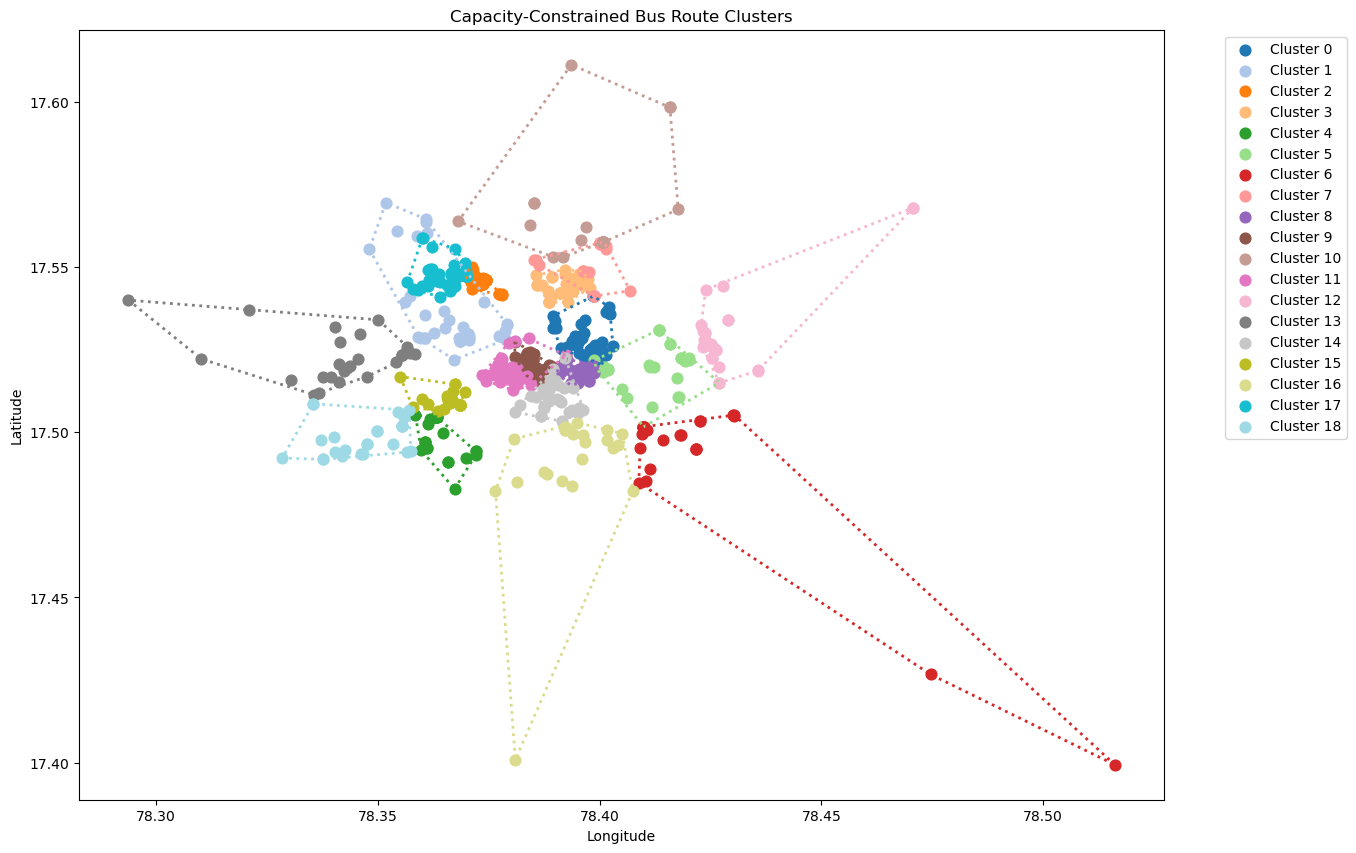

In [13]:
from scipy.spatial import ConvexHull

# =========================================================
# BUS CAPACITIES
# =========================================================

bus_capacities = [
    50,40,50,40,26,50,
    31,34,34,40,36,
    40,40,40,40,40,
    40,40,40
]

n_clusters = len(bus_capacities)

# =========================================================
# VALID DATA
# =========================================================

valid_mask = (
    df['Latitude'].notna() &
    df['Longitude'].notna()
)

X = df.loc[
    valid_mask,
    ['Longitude', 'Latitude']
].copy()

X_array = X.to_numpy()

# =========================================================
# INITIAL CLUSTERING
# =========================================================
# IMPORTANT:
# KMeansConstrained CANNOT assign different max size
# per cluster directly.
#
# So first:
# - create balanced clusters
# - then reassign overflow points
#
# This is the correct workaround.
# =========================================================

clf = KMeansConstrained(
    n_clusters=n_clusters,
    size_min=min(bus_capacities),
    size_max=max(bus_capacities),
    random_state=42
)

clusters = clf.fit_predict(X_array)

# =========================================================
# FIX OVERFLOW CLUSTERS
# =========================================================

cluster_series = pd.Series(clusters)

cluster_counts = (
    cluster_series
    .value_counts()
    .sort_index()
)

# Cluster centers
centers = clf.cluster_centers_

# =========================================================
# FORCE EACH CLUSTER TO RESPECT
# ITS OWN BUS CAPACITY
# =========================================================

for cluster_id in range(n_clusters):

    current_size = cluster_counts[cluster_id]
    max_capacity = bus_capacities[cluster_id]

    # Skip valid clusters
    if current_size <= max_capacity:
        continue

    # Overflow amount
    overflow = current_size - max_capacity

    # Points in this cluster
    idx_in_cluster = np.where(clusters == cluster_id)[0]

    cluster_points = X_array[idx_in_cluster]

    # Distance from centroid
    centroid = centers[cluster_id]

    distances = np.linalg.norm(
        cluster_points - centroid,
        axis=1
    )

    # Farthest points first
    sorted_idx = np.argsort(distances)[::-1]

    moved = 0

    for point_local_idx in sorted_idx:

        if moved >= overflow:
            break

        global_idx = idx_in_cluster[point_local_idx]

        point = X_array[global_idx]

        # Find nearest cluster with free space
        possible_clusters = []

        for target_cluster in range(n_clusters):

            if target_cluster == cluster_id:
                continue

            target_size = np.sum(clusters == target_cluster)

            if target_size < bus_capacities[target_cluster]:

                target_center = centers[target_cluster]

                dist = np.linalg.norm(
                    point - target_center
                )

                possible_clusters.append(
                    (target_cluster, dist)
                )

        if len(possible_clusters) == 0:
            continue

        # Nearest available cluster
        possible_clusters.sort(key=lambda x: x[1])

        best_cluster = possible_clusters[0][0]

        clusters[global_idx] = best_cluster

        moved += 1

# =========================================================
# SAVE FINAL CLUSTERS
# =========================================================

df['Cluster'] = pd.NA
df.loc[valid_mask, 'Cluster'] = clusters

# =========================================================
# FINAL CLUSTER COUNTS
# =========================================================

final_counts = (
    pd.Series(clusters)
    .value_counts()
    .sort_index()
)

# =========================================================
# PLOT
# =========================================================

plt.figure(figsize=(14,10))

cmap = plt.cm.get_cmap('tab20', n_clusters)

for cluster_id in range(n_clusters):

    cluster_points = X[clusters == cluster_id]

    # Scatter
    plt.scatter(
        cluster_points['Longitude'],
        cluster_points['Latitude'],
        color=cmap(cluster_id),
        s=60,
        label=f'Cluster {cluster_id}'
    )

    # Convex hull boundary
    if len(cluster_points) >= 3:

        points = cluster_points.to_numpy()

        hull = ConvexHull(points)

        hull_points = points[hull.vertices]

        hull_points = np.append(
            hull_points,
            [hull_points[0]],
            axis=0
        )

        plt.plot(
            hull_points[:,0],
            hull_points[:,1],
            linestyle='dotted',
            color=cmap(cluster_id),
            linewidth=2
        )

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Capacity-Constrained Bus Route Clusters")

plt.legend(
    bbox_to_anchor=(1.05,1),
    loc='upper left'
)

plt.show()

In [14]:
cluster_sizes = pd.Series(clusters).value_counts().sort_index()

In [15]:
student_counts = cluster_sizes.values

# -----------------------------
# BUS CAPACITIES
# -----------------------------
bus_capacities = [
    40,40,50,36,40,34,
    50,50,40,40,40,40,40,
    40,40,31,34,40,26
]

# -----------------------------
# ASSIGN BUSES
# -----------------------------
available_buses = sorted(bus_capacities)

assigned_buses = []

for students in student_counts:

    suitable_bus = None

    # Find smallest bus that fits
    for bus in available_buses:
        if bus >= students:
            suitable_bus = bus
            break

    # If no bus fits, assign largest remaining
    if suitable_bus is None:
        suitable_bus = max(available_buses)

    available_buses.remove(suitable_bus)
    assigned_buses.append(suitable_bus)

# -----------------------------
# FREE SPACE
# -----------------------------
free_space = [
    bus - students
    for bus, students in zip(assigned_buses, student_counts)
]

# -----------------------------
# CREATE TABLE
# -----------------------------
routes = [f"{i}" for i in range(len(student_counts))]

bus_df = pd.DataFrame(
    [student_counts, assigned_buses, free_space],
    index=["Student count", "Bus capacity", "Freespace"],
    columns=routes
)

# Add totals column
bus_df["Total"] = bus_df.sum(axis=1)

# -----------------------------
# STYLE TABLE
# -----------------------------
styled_df_bus = (
    bus_df.style
    .set_properties(**{
        'text-align': 'center',
        'font-size': '14px',
        'border': '1px solid black'
    })
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('background-color', '#2F4F7F'),
                ('color', 'white'),
                ('font-size', '16px'),
                ('text-align', 'center'),
                ('padding', '10px')
            ]
        },
        {
            'selector': 'td',
            'props': [
                ('padding', '10px'),
                ('text-align', 'center')
            ]
        }
    ])
)

display(styled_df_bus)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,Total
Student count,50,39,50,40,26,29,26,34,34,40,27,31,26,26,33,26,26,40,26,629
Bus capacity,50,40,50,40,26,31,34,34,36,40,40,40,40,40,40,40,40,40,50,751
Freespace,0,1,0,0,0,2,8,0,2,0,13,9,14,14,7,14,14,0,24,122


In [16]:
df.head(100)

,Student Name,ERP No.,Address,Clean Address,Route,"Latitude , Longitude",Latitude,Longitude,Cluster
0,Orchids International School,-,Orchid International School Bachupally,Orchid International School Bachupally,NaN,"17.557062061125425, 78.40006152438659",17.557062,78.400062,7
1,Vishaal,2609320090,"Huda colony,chanda nagar","Huda Colony, Chanda Nagar, Hyderabad, Telangana",1.0,"17.492239991437522, 78.32842944232877",17.492240,78.328429,18
2,M. Gaurangi,2609320253,My home jewel,"My Home Jewel, Miyapur, Hyderabad, Telangana",1.0,"17.491804778589852, 78.33762600775204",17.491805,78.337626,18
3,M. nitya,2609320257,My home jewel,"My Home Jewel, Miyapur, Hyderabad, Telangana",1.0,"17.491804778589852, 78.33762600775204",17.491805,78.337626,18
4,Dhaivik .V,2609320195,"Pranam hosptial, Madeenaguda","Pranam Hospital, Madeenaguda, Hyderabad, Telan...",1.0,"17.494635537783186, 78.3426860776248",17.494636,78.342686,18
...,...,...,...,...,...,...,...,...,...
95,SOURISH . KAMINENI,2509320056_OIS,"284, 2nd floor, ROAD NO.8/4, Vasanth Nagar","284, 2nd Floor, Road No 8/4, Vasanth Nagar, Hy...",3.0,"17.495219597134533, 78.40913229554069",17.495220,78.409132,6
96,Chidvilash Annam,2309320432_OIS,"Plot no 118, Ground floor, Road no 5/1, Vasant...","Plot 118, Ground Floor, Road No 5/1, Vasanta N...",3.0,"17.49181184676895, 78.3960859646749",17.491812,78.396086,16
97,V. Mokshith Ram . .Chowdary,2509320072_OIS,"Oxygen homes, survey no. 350, near to aero nag...","Oxygen Homes, Survey No 350, Near Aero Nagar, ...",3.0,"17.541234571675666, 78.39860274766077",17.541235,78.398603,0
98,Dhruva Nandan .Pabba,2309320532_OIS,"B403,Ramky one Marvel, Gajularamaram, hyd,500055.","Flat B403, Ramky One Marvel, Gajularamaram, Hy...",5.0,"17.521787059695992, 78.42024755136215",17.521787,78.420248,5


In [17]:
df.to_excel("final_route_students.xlsx", index=False)

In [8]:
from scipy.spatial.distance import cdist

# =========================================================
# READ EXISTING CSV FILE
# =========================================================

assign_df = pd.read_csv("C:/Users/ASUS/OneDrive/Desktop/Operations Route Problem/final_route_cluster.csv" , encoding='latin1')

# =========================================================
# BUS CAPACITY
# =========================================================

bus_capacities = {
    0:50,
    1:40,
    2:50,
    3:40,
    4:26,
    5:31,
    6:34,
    7:34,
    8:36,
    9:40,
    10:40,
    11:40,
    12:40,
    13:40,
    14:40,
    15:40,
    16:40,
    17:40,
    18:50
}

# =========================================================
# REMOVE INVALID COORDINATES
# =========================================================

valid_df = assign_df[
    assign_df['Latitude'].notna() &
    assign_df['Longitude'].notna() &
    assign_df['Cluster'].notna()
].copy()

# =========================================================
# CURRENT CLUSTER COUNT
# =========================================================

cluster_counts = (
    valid_df['Cluster']
    .value_counts()
    .sort_index()
)

# Ensure all clusters exist
for cluster_id in bus_capacities.keys():

    if cluster_id not in cluster_counts:
        cluster_counts[cluster_id] = 0

cluster_counts = cluster_counts.sort_index()

# =========================================================
# CALCULATE CLUSTER CENTROIDS
# =========================================================

cluster_centroids = {}

for cluster_id in bus_capacities.keys():

    cluster_points = valid_df[
        valid_df['Cluster'] == cluster_id
    ]

    centroid_lat = cluster_points['Latitude'].mean()
    centroid_lon = cluster_points['Longitude'].mean()

    cluster_centroids[cluster_id] = (
        centroid_lon,
        centroid_lat
    )

# =========================================================
# FUNCTION:
# ASSIGN NEW STUDENT
# =========================================================

def assign_new_student(
    latitude,
    longitude
):

    global cluster_counts

    # ---------------------------------------------
    # NEW STUDENT POINT
    # ---------------------------------------------

    new_point = np.array([
        [longitude, latitude]
    ])

    # ---------------------------------------------
    # DISTANCE FROM ALL CLUSTERS
    # ---------------------------------------------

    cluster_ids = []
    centroid_points = []

    for cluster_id, center in cluster_centroids.items():

        cluster_ids.append(cluster_id)
        centroid_points.append(center)

    centroid_points = np.array(centroid_points)

    distances = cdist(
        new_point,
        centroid_points
    )[0]

    # Nearest clusters first
    nearest_order = np.argsort(distances)

    assigned_cluster = None

    # ---------------------------------------------
    # FIND CLUSTER WITH FREE SPACE
    # ---------------------------------------------

    for idx in nearest_order:

        cluster_id = cluster_ids[idx]

        current_students = cluster_counts[cluster_id]

        capacity = bus_capacities[cluster_id]

        # Check vacancy
        if current_students < capacity:

            assigned_cluster = cluster_id

            # Update student count
            cluster_counts[cluster_id] += 1

            remaining_space = (
                capacity -
                cluster_counts[cluster_id]
            )

            print(f"""
            ====================================
            STUDENT ASSIGNED SUCCESSFULLY
            ====================================

            Assigned Cluster : {assigned_cluster}

            Current Students : {cluster_counts[cluster_id]}

            Bus Capacity     : {capacity}

            Remaining Seats  : {remaining_space}
            """)

            return assigned_cluster

    # ---------------------------------------------
    # ALL BUSES FULL
    # ---------------------------------------------

    print("No Bus Available")

    return None

In [7]:
assign_new_student(
    latitude=17.517517521458117,
    longitude=78.39818110904123
)


            STUDENT ASSIGNED SUCCESSFULLY

            Assigned Cluster : 8

            Current Students : 35

            Bus Capacity     : 36

            Remaining Seats  : 1
            


8